# Synthetic towers
Real towers fail because training photos have one big brick on a plain table (see the end of test_real.ipynb).
Here we build tower-like training scenes from the bricks we already have:
1. **Cut out** each brick from its photo (GrabCut, using our known box as the starting point).
2. **Paste** many cutouts, small, stacked and overlapping, onto busy backgrounds; boxes come free.
3. **Train** YOLO on synthetic + original photos, then test on `real/`.

Only **train-split** photos are cut out, so the compare.ipynb test split stays unseen.

In [8]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, os, glob, random, shutil
from collections import defaultdict
from multiprocessing import Pool
import cv2, numpy as np, matplotlib.pyplot as plt

S = 1024 / 4032   # cache1024 scale
boxes = {r['path']: (r['element_id'], *[float(r[k]) * S for k in ('x0', 'y0', 'x1', 'y1')]) for r in csv.DictReader(open('data/boxes.csv'))}
ranges = [(int(r['start']), int(r['end'])) for r in csv.DictReader(open('data/ranges.csv'))]
em = {r['element_id']: r for r in csv.DictReader(open('data/element_map.csv'))}
CLASSES = sorted({b[0] for b in boxes.values()}); CI = {c: i for i, c in enumerate(CLASSES)}

# same per-run 70/15/15 split as compare.ipynb
run_of = lambda p: next(i for i, (a, b) in enumerate(ranges) if a <= int(os.path.basename(p)[4:8]) <= b)
split, runs = {}, defaultdict(list)
for p in boxes: runs[run_of(p)].append(p)
for ps in runs.values():
    ps.sort()
    for i, p in enumerate(ps): split[p] = 'train' if i < 0.7 * len(ps) else 'val' if i < 0.85 * len(ps) else 'test'
TRAIN = [p for p in boxes if split[p] == 'train']
print(len(CLASSES), 'classes,', len(TRAIN), 'train photos')

41 classes, 4564 train photos


## 1. Cut out bricks (~2-3 min, cached in `cutouts/`)

1640 of 1640 cutouts ok; fewest per class: 40


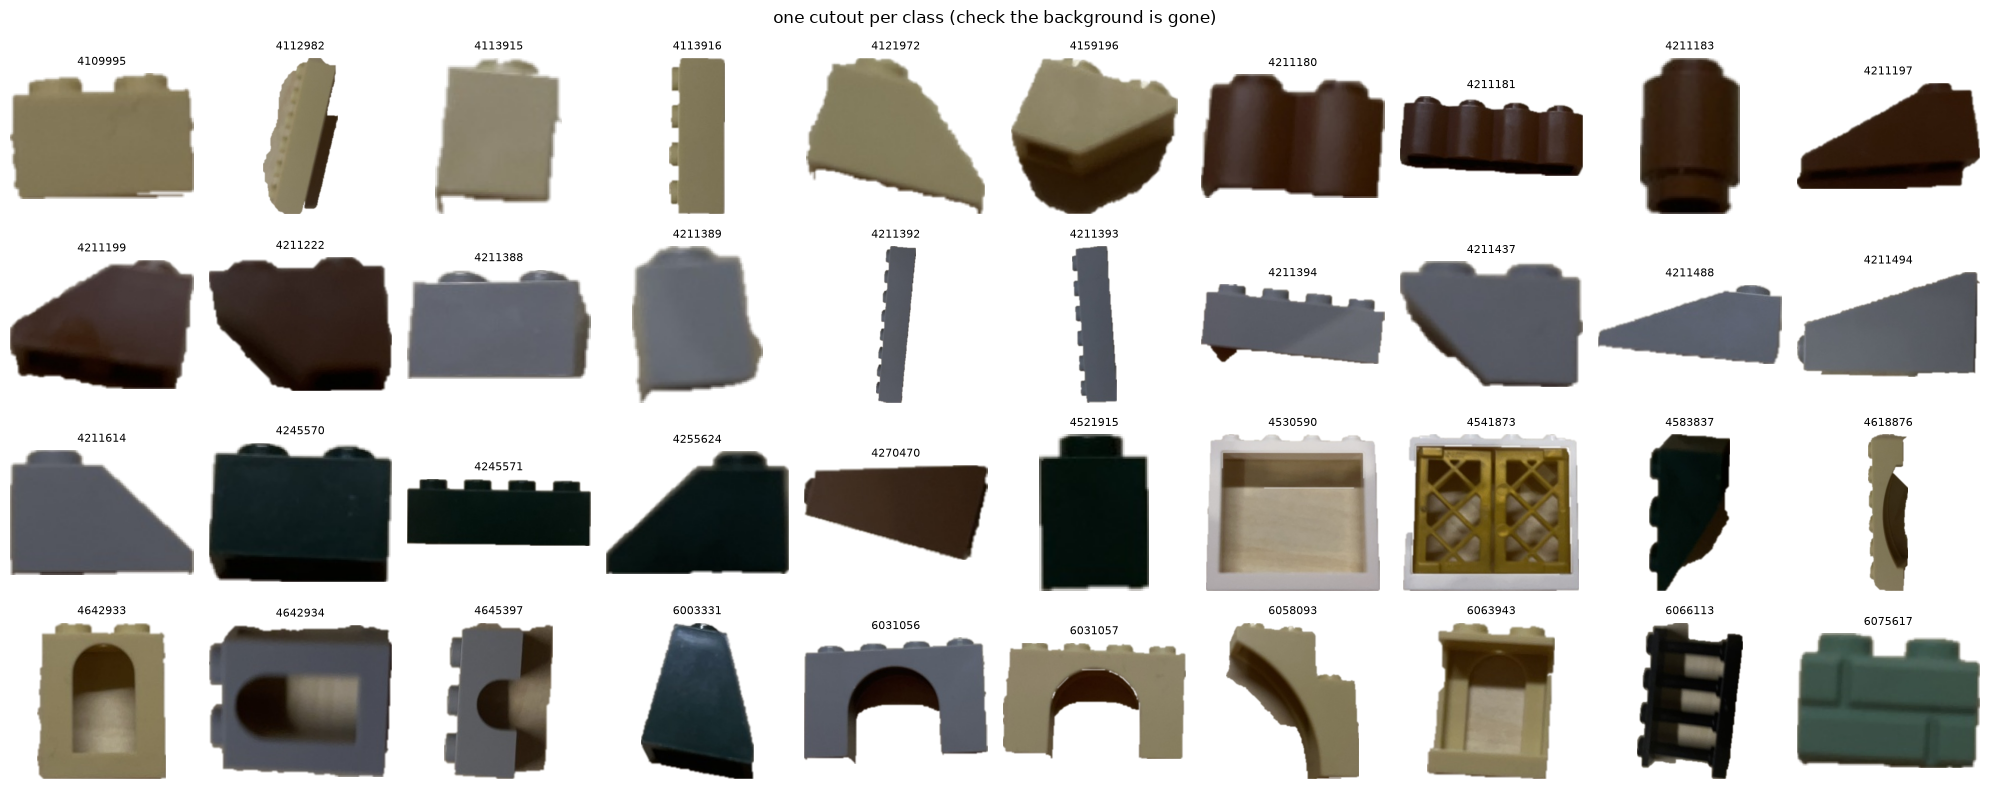

In [9]:
PER_CLASS = 40   # cutouts per class; spread evenly over each class's train photos

def cut(p):
    e, x0, y0, x1, y1 = boxes[p]
    out = f'cutouts/{e}/{os.path.basename(p)[:-4]}.png'
    if os.path.exists(out): return out
    im = cv2.imread('cache1024/' + p)
    m = 12   # margin of table around the box so GrabCut sees background
    X0, Y0 = max(int(x0) - m, 0), max(int(y0) - m, 0)
    X1, Y1 = min(int(x1) + m, im.shape[1]), min(int(y1) + m, im.shape[0])
    crop = im[Y0:Y1, X0:X1].copy()
    mask = np.zeros(crop.shape[:2], np.uint8)
    rect = (int(x0) - X0, int(y0) - Y0, max(int(x1 - x0), 2), max(int(y1 - y0), 2))
    try: cv2.grabCut(crop, mask, rect, np.zeros((1, 65)), np.zeros((1, 65)), 4, cv2.GC_INIT_WITH_RECT)
    except cv2.error: return None
    fg = np.isin(mask, (1, 3)).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(fg)   # keep the biggest blob, drop specks
    if n < 2: return None
    fg = (lab == 1 + st[1:, cv2.CC_STAT_AREA].argmax()).astype(np.uint8)
    if fg.sum() < 0.15 * rect[2] * rect[3]: return None   # GrabCut lost the brick
    ys, xs = np.nonzero(fg)
    rgba = np.dstack([crop, cv2.GaussianBlur(fg * 255, (3, 3), 0)])[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    os.makedirs(os.path.dirname(out), exist_ok=True); cv2.imwrite(out, rgba)
    return out

by_cls = defaultdict(list)
for p in sorted(TRAIN): by_cls[boxes[p][0]].append(p)
todo = [ps[int(i)] for ps in by_cls.values() for i in np.linspace(0, len(ps) - 1, min(PER_CLASS, len(ps)))]
with Pool() as pool: done = [c for c in pool.map(cut, todo, chunksize=8) if c]
CUT = defaultdict(list)
for c in done: CUT[c.split('/')[1]].append(c)
print(len(done), 'of', len(todo), 'cutouts ok; fewest per class:', min(len(v) for v in CUT.values()))
assert len(CUT) == len(CLASSES), 'every class needs cutouts'

fig, ax = plt.subplots(4, 10, figsize=(20, 8))
for a, c in zip(ax.flat, CLASSES):
    im = cv2.imread(random.choice(CUT[c]), cv2.IMREAD_UNCHANGED)
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGRA2RGBA)); a.set_title(c, fontsize=8); a.axis('off')
plt.suptitle('one cutout per class (check the background is gone)'); plt.tight_layout(); plt.show()

## 2. Build scenes
Each scene: a busy background, then several **stacks** (bricks piled bottom-up, overlapping like a tower) plus a few loose bricks.
Bricks are 4-25% of the scene wide, matching real tower photos. A brick covered more than 70% by later bricks loses its label.

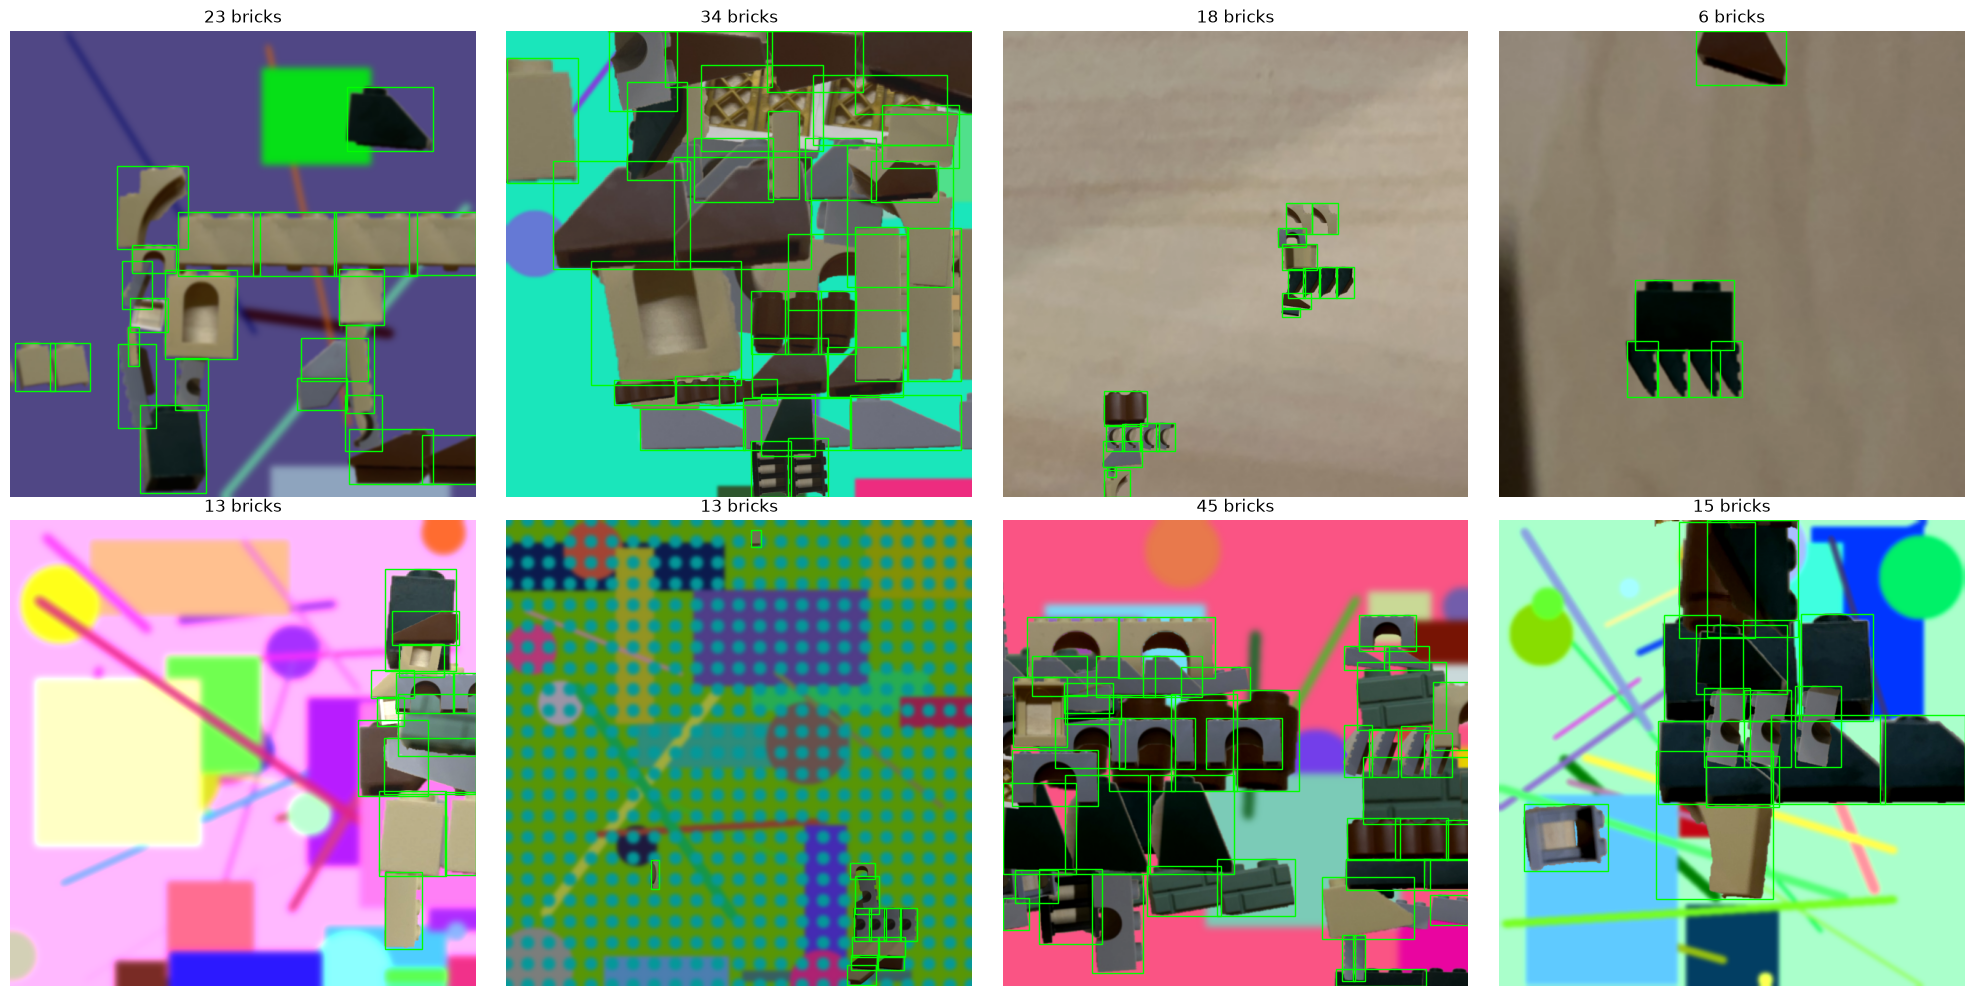

In [10]:
SZ = 640
TABLE = [p for p in TRAIN]   # plain-table photos, used as one kind of background

def background(rng):
    if rng.random() < 0.3:   # empty patch of a real table photo (must avoid its own brick, which has no label here)
        p = rng.choice(TABLE); _, bx0, by0, bx1, by1 = boxes[p]
        for _ in range(20):
            s = rng.integers(150, 500); y, x = rng.integers(0, 768 - s + 1), rng.integers(0, 1024 - s + 1)
            if x + s < bx0 or x > bx1 or y + s < by0 or y > by1:
                return cv2.resize(cv2.imread('cache1024/' + p)[y:y+s, x:x+s], (SZ, SZ))
    bg = np.full((SZ, SZ, 3), rng.integers(0, 256, 3), np.uint8)   # clutter: like a desk, keyboard, base plate
    for _ in range(rng.integers(5, 40)):
        c = tuple(int(v) for v in rng.integers(0, 256, 3)); x, y = rng.integers(0, SZ, 2)
        k = rng.integers(3)
        if k == 0: cv2.rectangle(bg, (x, y), (x + rng.integers(10, 300), y + rng.integers(10, 300)), c, -1)
        elif k == 1: cv2.circle(bg, (x, y), int(rng.integers(3, 60)), c, -1)
        else: cv2.line(bg, (x, y), tuple(int(v) for v in rng.integers(0, SZ, 2)), c, int(rng.integers(1, 15)))
    if rng.random() < 0.5:   # stud grid, like a base plate / keyboard
        st = int(rng.integers(8, 30)); c = tuple(int(v) for v in rng.integers(0, 256, 3))
        for yy in range(0, SZ, st):
            for xx in range(0, SZ, st): cv2.circle(bg, (xx, yy), st // 3, c, -1)
    return cv2.GaussianBlur(bg, (0, 0), rng.uniform(0.5, 6))   # real backgrounds are out of focus

def paste(img, ids, cut, x, y, k):
    h, w = cut.shape[:2]
    a0, b0 = max(x, 0), max(y, 0); a1, b1 = min(x + w, SZ), min(y + h, SZ)
    if a1 <= a0 or b1 <= b0: return False
    c = cut[b0 - y:b1 - y, a0 - x:a1 - x]; al = c[..., 3:] / 255
    img[b0:b1, a0:a1] = (c[..., :3] * al + img[b0:b1, a0:a1] * (1 - al)).astype(np.uint8)
    ids[b0:b1, a0:a1][al[..., 0] > 0.5] = k
    return True

def load(rng, scale_px):
    c = rng.choice(CLASSES); im = cv2.imread(rng.choice(CUT[c]), cv2.IMREAD_UNCHANGED)
    if rng.random() < 0.5: im = im[:, ::-1]
    f = scale_px / max(im.shape[:2])
    return c, cv2.resize(np.ascontiguousarray(im), None, fx=f, fy=f, interpolation=cv2.INTER_AREA)

def scene(seed):
    rng = np.random.default_rng(seed)
    img, ids = background(rng), np.zeros((SZ, SZ), np.int32)
    unit = rng.uniform(0.04, 0.25) * SZ   # brick size for this scene (towers have similar-size bricks)
    placed = []   # (class, own area)
    for _ in range(rng.integers(1, 6)):   # stacks
        x, y = int(rng.uniform(-0.2, 0.9) * SZ), int(rng.uniform(0.5, 1.1) * SZ)
        for _ in range(rng.integers(2, 9)):
            c, cut = load(rng, unit * rng.uniform(0.6, 1.6))
            h, w = cut.shape[:2]
            # real towers repeat bricks: often a row of 2-4 identical ones touching, side by side
            n = rng.integers(2, 5) if rng.random() < 0.4 else 1
            x1 = x + int(rng.normal(0, w * 0.15))
            for j in range(n):
                if paste(img, ids, cut, x1 + int(j * w * rng.uniform(0.85, 1.0)), y - h, len(placed) + 1):
                    placed.append((c, (cut[..., 3] > 127).sum()))
            y -= int(h * rng.uniform(0.6, 0.95))   # next brick sits on top, overlapping a bit
    for _ in range(rng.integers(0, 6)):   # loose bricks
        c, cut = load(rng, unit * rng.uniform(0.6, 1.6))
        if paste(img, ids, cut, *rng.integers(-cut.shape[1] // 2, SZ, 2), len(placed) + 1):
            placed.append((c, (cut[..., 3] > 127).sum()))
    labels = []
    for k, (c, area) in enumerate(placed, 1):
        ys, xs = np.nonzero(ids == k)
        if len(xs) < 0.3 * area or len(xs) < 30: continue   # mostly hidden or off-screen
        x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
        labels.append((CI[c], (x0 + x1) / 2 / SZ, (y0 + y1) / 2 / SZ, (x1 - x0) / SZ, (y1 - y0) / SZ))
    # whole-scene photo effects (no hue change: color is part of the class)
    img = np.clip(img * rng.uniform(0.7, 1.3) + rng.uniform(-30, 30), 0, 255).astype(np.uint8)
    if rng.random() < 0.3: img = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.5, 1.5))
    return img, labels

assert all(0 <= v <= 1 for _, l in [scene(i) for i in range(20)] for b in l for v in b[1:]), 'boxes must be inside the scene'
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
for a, i in zip(ax.flat, range(8)):
    img, lab = scene(i); a.imshow(img[..., ::-1]); a.axis('off'); a.set_title(f'{len(lab)} bricks')
    for c, cx, cy, w, h in lab:
        a.add_patch(plt.Rectangle(((cx - w/2) * SZ, (cy - h/2) * SZ), w * SZ, h * SZ, fill=False, color='lime'))
plt.tight_layout(); plt.show()

## 3. Write the dataset (~2 min, cached in `synth/`)

In [11]:
N_TRAIN, N_VAL = 8000, 800
Y = 'synth_v2'   # v2 scenes (rows of identical bricks); v1 kept in synth/

def write(job):
    k, i = job
    if os.path.exists(f'{Y}/{k}/labels/{i}.txt'): return
    img, lab = scene(i if k == 'train' else 10**7 + i)
    cv2.imwrite(f'{Y}/{k}/images/{i}.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, 90])
    open(f'{Y}/{k}/labels/{i}.txt', 'w').write(''.join(f'{c} {a:.6f} {b:.6f} {w:.6f} {h:.6f}\n' for c, a, b, w, h in lab))

for k in ('train', 'val'):
    os.makedirs(f'{Y}/{k}/images', exist_ok=True); os.makedirs(f'{Y}/{k}/labels', exist_ok=True)
with Pool() as pool: pool.map(write, [('train', i) for i in range(N_TRAIN)] + [('val', i) for i in range(N_VAL)], chunksize=32)

# train on synthetic + the original single-brick photos (yolo41/ from compare.ipynb)
open(f'{Y}/data.yaml', 'w').write(f'path: {os.path.abspath(".")}\ntrain: [{Y}/train/images, yolo41/train/images]\nval: {Y}/val/images\nnames:\n'
                                  + ''.join(f'  {i}: "{c}"\n' for i, c in enumerate(CLASSES)))
print(len(os.listdir(f'{Y}/train/images')), 'train scenes,', len(os.listdir(f'{Y}/val/images')), 'val scenes')

8000 train scenes, 800 val scenes


## 4. Train YOLO (~1 h on the 3060; skipped if already trained)

In [12]:
from ultralytics import YOLO
found = glob.glob('runs/**/synth_yolo/weights/best.pt', recursive=True)
if not found:   # v1: from COCO weights
    YOLO('yolo11s.pt').train(data=f'{Y}/data.yaml', imgsz=640, epochs=40, batch=16, hsv_h=0, hsv_s=0.2, degrees=10,
                             mosaic=1.0, project=os.path.abspath('runs'), name='synth_yolo', exist_ok=True, verbose=False)
    found = glob.glob('runs/**/synth_yolo/weights/best.pt', recursive=True)
# v2: scenes now have rows of identical bricks -> short fine-tune of v1 (~25 min) instead of training from scratch
found2 = glob.glob('runs/**/synth_yolo_v2/weights/best.pt', recursive=True)
if not found2:
    YOLO(found[0]).train(data=f'{Y}/data.yaml', imgsz=640, epochs=15, batch=16, lr0=0.002, hsv_h=0, hsv_s=0.2, degrees=10,
                         mosaic=1.0, project=os.path.abspath('runs'), name='synth_yolo_v2', exist_ok=True, verbose=False)
    found2 = glob.glob('runs/**/synth_yolo_v2/weights/best.pt', recursive=True)
yolo = YOLO(found2[0])

Ultralytics 8.4.215 🚀 Python-3.12.16 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3060, 11907MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=synth_v2/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0.2, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=runs/synth_yolo/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=synth_yolo_v2, nbs=64, nms=None, opset=

## 5. Test on real towers (`real/`)

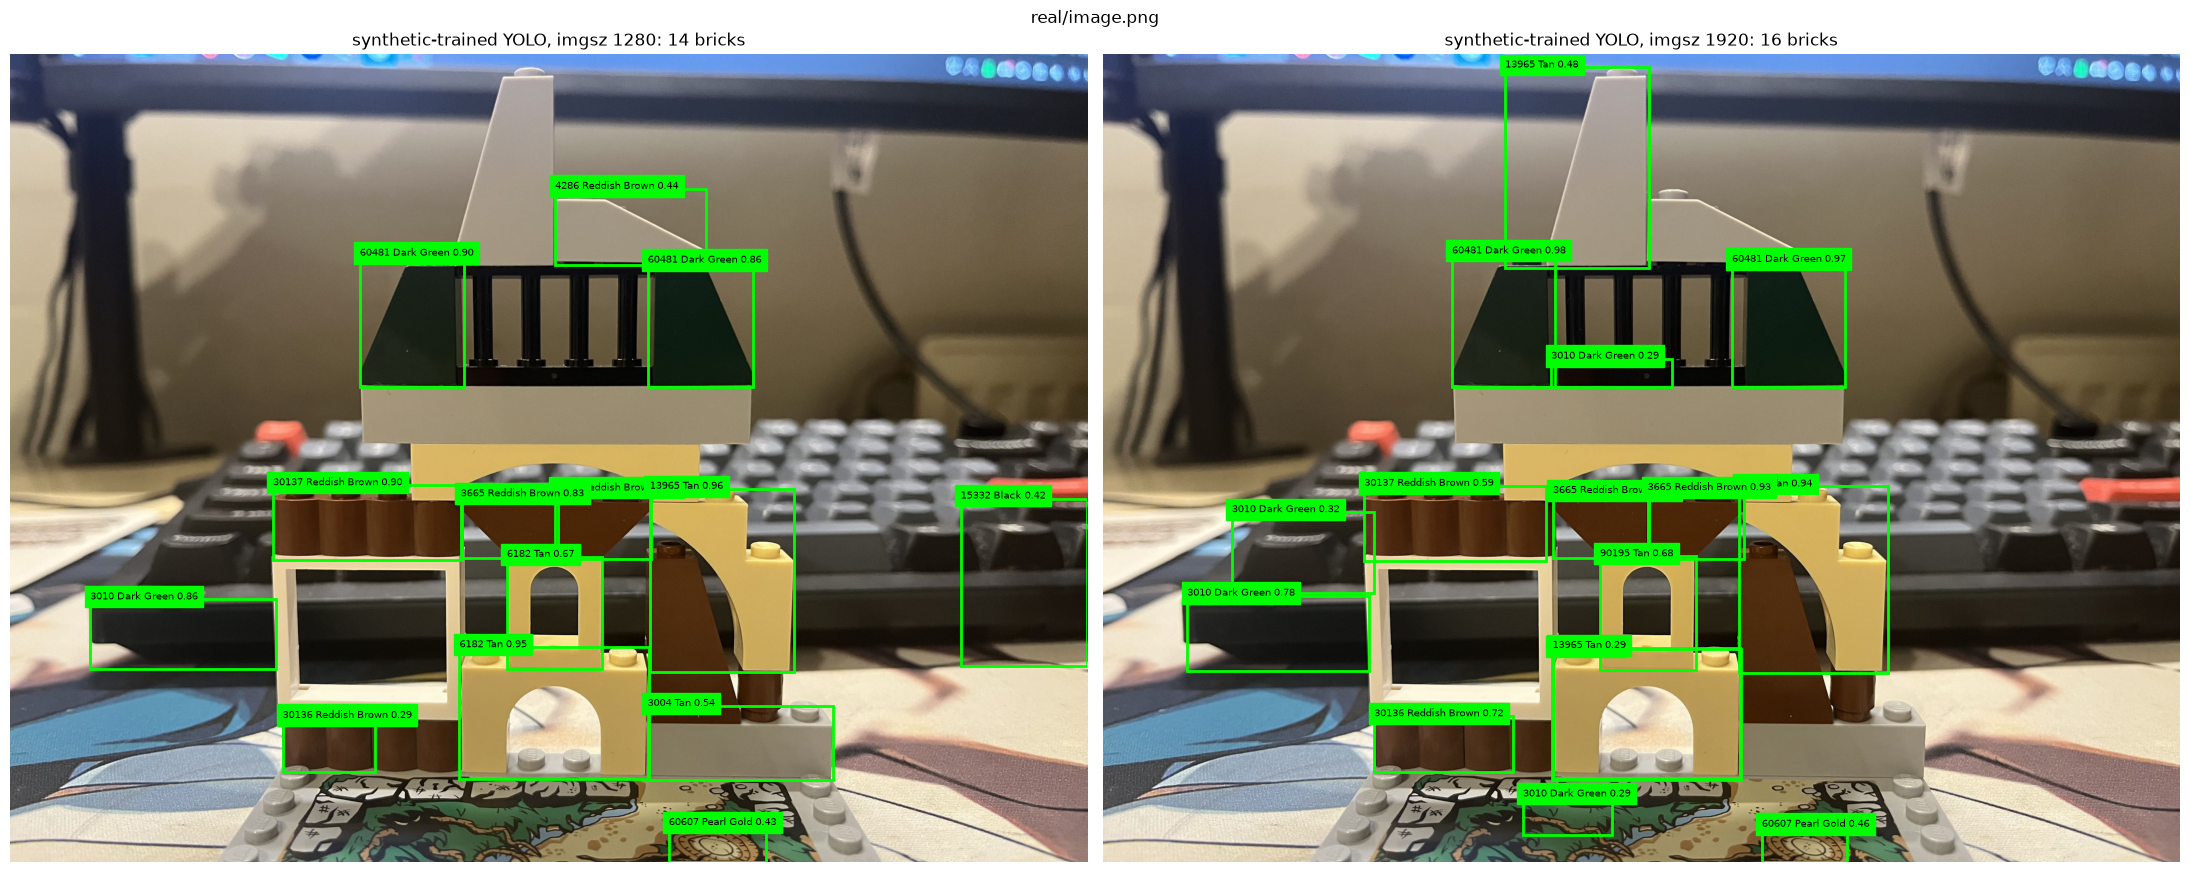

In [13]:
name = lambda c: f"{em[c]['part_num']} {em[c]['color']}"
for f in sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]')):
    img = cv2.imread(f)
    fig, ax = plt.subplots(1, 2, figsize=(22, 9))
    for a, sz in zip(ax, (1280, 1920)):   # 1280 = zoom in, smaller bricks become visible
        b = yolo.predict(img, imgsz=sz, conf=0.25, verbose=False)[0].boxes.cpu()
        a.imshow(img[..., ::-1]); a.axis('off'); a.set_title(f'synthetic-trained YOLO, imgsz {sz}: {len(b)} bricks')
        for (x0, y0, x1, y1), c, s in zip(b.xyxy.numpy(), b.cls.int().tolist(), b.conf.tolist()):
            a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color='lime', lw=2))
            a.text(x0, y0, f'{name(CLASSES[c])} {s:.2f}', fontsize=7, backgroundcolor='lime')
    fig.suptitle(f); plt.tight_layout(); plt.show()